<a href="https://colab.research.google.com/github/uditjaisw-cmyk/Optimizing-COD-Logistics-Routing/blob/main/Logistics_Routing_Engine_Udit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1 — Library Imports & Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
np.random.seed(42)

# Display settings
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams['figure.facecolor'] = '#0a0e17'
plt.rcParams['axes.facecolor']   = '#111827'
plt.rcParams['text.color']       = '#e2e8f0'
plt.rcParams['axes.labelcolor']  = '#94a3b8'
plt.rcParams['xtick.color']      = '#94a3b8'
plt.rcParams['ytick.color']      = '#94a3b8'
plt.rcParams['axes.spines.top']  = False
plt.rcParams['axes.spines.right']= False
plt.rcParams['axes.edgecolor']   = '#1f2d42'
plt.rcParams['grid.color']       = '#1f2d42'
plt.rcParams['grid.alpha']       = 0.5

print("✅ Libraries loaded successfully")
print(f"   pandas  {pd.__version__}")
print(f"   numpy   {np.__version__}")
print(f"   matplotlib loaded")


✅ Libraries loaded successfully
   pandas  2.2.3
   numpy   2.1.3
   matplotlib loaded


## Step 2 — Data Generation (10,000 Synthetic Orders)


- **75% COD / 25% Prepaid** — mirrors Indian e-commerce payment split  
- **Valmo covers 72% of PIN codes** — based on asset-light network limitation  
- **High-value orders (>₹2,200) → 3PL** — safety routing for insurance  
- **COD PIN risk: 30–60%** vs **Prepaid: 5–15%** — reflects higher COD return rates


In [ ]:
n_orders = 10_000

df = pd.DataFrame({
    'Order_ID'            : range(10001, 10001 + n_orders),
    'Order_Value_INR'     : np.random.randint(150, 2500, n_orders),
    'Is_COD'              : np.random.choice([1, 0], n_orders, p=[0.75, 0.25]),
    'Customer_Return_Hist': np.random.uniform(0.0, 0.5,  n_orders).round(3),
    'Valmo_Cost'          : np.random.uniform(35.0, 42.0, n_orders).round(2),
    '3PL_Cost'            : np.random.uniform(50.0, 65.0, n_orders).round(2),
})

# Derived columns
df['Payment_Type'] = np.where(df['Is_COD'] == 1, 'Cash on Delivery', 'Prepaid')

# Business constraints
df['Valmo_Serviceable'] = np.random.choice([True, False], n_orders, p=[0.72, 0.28])
df['High_Value_Order']  = df['Order_Value_INR'] > 2200

# Historical PIN Risk — COD zones are riskier
df['Historical_PIN_Risk'] = np.where(
    df['Is_COD'] == 1,
    np.random.uniform(0.30, 0.60, n_orders),   # COD: 30–60% RTO risk
    np.random.uniform(0.05, 0.15, n_orders)    # Prepaid: 5–15% RTO risk
).round(4)

print(f"✅ Dataset created: {len(df):,} orders")
print(f"\n{'─'*45}")
print(f"  COD orders      : {df['Is_COD'].sum():>6,}  ({df['Is_COD'].mean()*100:.1f}%)")
print(f"  Prepaid orders  : {(~df['Is_COD'].astype(bool)).sum():>6,}  ({(1-df['Is_COD'].mean())*100:.1f}%)")
print(f"  Valmo serviceable: {df['Valmo_Serviceable'].sum():>5,}  ({df['Valmo_Serviceable'].mean()*100:.1f}%)")
print(f"  High-value orders: {df['High_Value_Order'].sum():>5,}  ({df['High_Value_Order'].mean()*100:.1f}%)")
print(f"{'─'*45}")
df.head(5)


✅ Dataset created: 10,000 orders

─────────────────────────────────────────────
  COD orders      :  7,589  (75.9%)
  Prepaid orders  :  2,411  (24.1%)
  Valmo serviceable: 7,102  (71.0%)
  High-value orders: 1,208  (12.1%)
─────────────────────────────────────────────


,Order_ID,Order_Value_INR,Is_COD,Customer_Return_Hist,Valmo_Cost,3PL_Cost,Payment_Type,Valmo_Serviceable,High_Value_Order,Historical_PIN_Risk
0,10001,1010,1,0.18,39.27,61.09,Cash on Delivery,False,False,0.52
1,10002,1444,0,0.17,41.81,64.84,Prepaid,True,False,0.14
2,10003,1280,0,0.38,41.55,58.07,Prepaid,False,False,0.10
3,10004,1245,1,0.22,35.07,60.74,Cash on Delivery,True,False,0.30
4,10005,1788,1,0.39,35.56,56.62,Cash on Delivery,True,False,0.45


## Step 3 — Exploratory Data Analysis

In [ ]:
# ── SQL Query 1: RTO Risk by Payment Type ──────────────────────────────────
# Equivalent SQL:
# SELECT Payment_Type,
#        COUNT(Order_ID)                              AS Total_Orders,
#        ROUND(AVG(Historical_PIN_Risk) * 100, 2)    AS Avg_RTO_Pct,
#        ROUND(AVG(Valmo_Cost), 2)                   AS Avg_Valmo_Cost,
#        ROUND(AVG(\'3PL_Cost\'), 2)                  AS Avg_3PL_Cost
# FROM   MidSem_PowerBI_Data
# GROUP  BY Payment_Type;

q1 = (df.groupby('Payment_Type')
        .agg(
            Total_Orders       = ('Order_ID',           'count'),
            Avg_RTO_Pct        = ('Historical_PIN_Risk', lambda x: round(x.mean()*100, 2)),
            Avg_Valmo_Cost     = ('Valmo_Cost',          lambda x: round(x.mean(), 2)),
            Avg_3PL_Cost       = ('3PL_Cost',            lambda x: round(x.mean(), 2)),
        )
        .reset_index())

print("📊 SQL Query 1 — RTO Risk & Cost by Payment Type")
print("="*60)
print(q1.to_string(index=False))


📊 SQL Query 1 — RTO Risk & Cost by Payment Type
    Payment_Type  Total_Orders  Avg_RTO_Pct  Avg_Valmo_Cost  Avg_3PL_Cost
Cash on Delivery          7589        45.08           38.47         57.51
         Prepaid          2411         9.92           38.52         57.66


In [ ]:
# ── SQL Query 2: Orders Forced to 3PL Due to Business Rules ────────────────
# SELECT
#   SUM(CASE WHEN Valmo_Serviceable = FALSE THEN 1 ELSE 0 END) AS No_Coverage,
#   SUM(CASE WHEN High_Value_Order  = TRUE  THEN 1 ELSE 0 END) AS High_Value,
#   SUM(CASE WHEN Valmo_Serviceable = TRUE
#            AND High_Value_Order   = FALSE THEN 1 ELSE 0 END) AS EMV_Eligible
# FROM MidSem_PowerBI_Data;

no_cov   = (~df['Valmo_Serviceable']).sum()
hi_val   = (df['Valmo_Serviceable'] & df['High_Value_Order']).sum()
eligible = (df['Valmo_Serviceable'] & ~df['High_Value_Order']).sum()

print("📊 SQL Query 2 — Order Segmentation by Routing Rule")
print("="*60)
print(f"  Rule 1 — No Valmo coverage (forced 3PL) : {no_cov:>5,}  ({no_cov/n_orders*100:.1f}%)")
print(f"  Rule 2 — High-value safety (prefer 3PL) : {hi_val:>5,}  ({hi_val/n_orders*100:.1f}%)")
print(f"  Rule 3 — EMV comparison eligible        : {eligible:>5,}  ({eligible/n_orders*100:.1f}%)")
print(f"{'─'*60}")
print(f"  Total                                   : {n_orders:>5,} (100.0%)")


📊 SQL Query 2 — Order Segmentation by Routing Rule
  Rule 1 — No Valmo coverage (forced 3PL) : 2,898  (29.0%)
  Rule 2 — High-value safety (prefer 3PL) :   879  (8.8%)
  Rule 3 — EMV comparison eligible        : 6,223  (62.2%)
────────────────────────────────────────────────────────────
  Total                                   : 10,000 (100.0%)


In [ ]:
# ── SQL Query 3: High-Risk PIN Code Analysis ────────────────────────────────
# SELECT
#   CASE WHEN Historical_PIN_Risk >= 0.4 THEN 'High Risk (>=40%)'
#        WHEN Historical_PIN_Risk >= 0.2 THEN 'Medium Risk (20-40%)'
#        ELSE 'Low Risk (<20%)'
#   END AS Risk_Tier,
#   COUNT(*) AS Orders,
#   ROUND(AVG(Historical_PIN_Risk)*100,1) AS Avg_RTO_Pct
# FROM MidSem_PowerBI_Data GROUP BY Risk_Tier;

df['Risk_Tier'] = pd.cut(
    df['Historical_PIN_Risk'],
    bins=[0, 0.20, 0.40, 1.0],
    labels=['Low Risk (<20%)', 'Medium Risk (20-40%)', 'High Risk (>40%)']
)

q3 = (df.groupby('Risk_Tier', observed=True)
        .agg(Orders=('Order_ID','count'),
             Avg_RTO_Pct=('Historical_PIN_Risk', lambda x: round(x.mean()*100,1)))
        .reset_index())

print("📊 SQL Query 3 — Orders by Risk Tier")
print("="*60)
print(q3.to_string(index=False))


📊 SQL Query 3 — Orders by Risk Tier
           Risk_Tier  Orders  Avg_RTO_Pct
     Low Risk (<20%)    2411         9.90
Medium Risk (20-40%)    2527        35.10
    High Risk (>40%)    5062        50.10


## Step 4 — EMV Calculations




In [ ]:
# Vectorized EMV calculations across all 10,000 orders
df['EMV_Valmo'] = (df['Historical_PIN_Risk'] * (df['Valmo_Cost'] * 2)).round(4)
df['EMV_3PL']   = (df['Historical_PIN_Risk'] * (df['3PL_Cost']   * 2)).round(4)
df['EMV_Delta'] = (df['EMV_3PL'] - df['EMV_Valmo']).round(4)  # positive = Valmo cheaper

print("✅ EMV calculations complete")
print(f"\n{'─'*50}")
print(f"  Avg EMV Loss — Valmo : ₹{df['EMV_Valmo'].mean():.2f} per order")
print(f"  Avg EMV Loss — 3PL   : ₹{df['EMV_3PL'].mean():.2f} per order")
print(f"  Avg EMV Delta        : ₹{df['EMV_Delta'].mean():.2f} (positive = Valmo cheaper)")
print(f"{'─'*50}")
print(f"\nSample — first 5 orders:")
df[['Order_ID','Payment_Type','Historical_PIN_Risk',
    'Valmo_Cost','3PL_Cost','EMV_Valmo','EMV_3PL','EMV_Delta']].head(5)


✅ EMV calculations complete

──────────────────────────────────────────────────
  Avg EMV Loss — Valmo : ₹28.16 per order
  Avg EMV Loss — 3PL   : ₹42.10 per order
  Avg EMV Delta        : ₹13.94 (positive = Valmo cheaper)
──────────────────────────────────────────────────

Sample — first 5 orders:


,Order_ID,Payment_Type,Historical_PIN_Risk,Valmo_Cost,3PL_Cost,EMV_Valmo,EMV_3PL,EMV_Delta
0,10001,Cash on Delivery,0.52,39.27,61.09,41.22,64.12,22.90
1,10002,Prepaid,0.14,41.81,64.84,11.81,18.31,6.50
2,10003,Prepaid,0.10,41.55,58.07,7.89,11.03,3.14
3,10004,Cash on Delivery,0.30,35.07,60.74,21.27,36.83,15.57
4,10005,Cash on Delivery,0.45,35.56,56.62,31.85,50.71,18.86


## Step 5 — Routing Decision Engine




In [ ]:
def route_order(row):
    """
    EMV-based routing decision engine.
    Returns: 'Valmo' or '3PL' with reason code
    """
    # Rule 1 — Serviceability
    if not row['Valmo_Serviceable']:
        return '3PL'
    # Rule 2 — High-value safety
    if row['High_Value_Order']:
        return '3PL'
    # Rule 3 — EMV comparison
    if row['EMV_Valmo'] <= row['EMV_3PL']:
        return 'Valmo'
    return '3PL'

df['Assigned_Partner']     = df.apply(route_order, axis=1)
df['Final_Fulfillment_Cost'] = np.where(
    df['Assigned_Partner'] == 'Valmo',
    df['Valmo_Cost'], df['3PL_Cost']
)
df['Cost_Saving_vs_3PL'] = df['3PL_Cost'] - df['Final_Fulfillment_Cost']

# ── Results ──────────────────────────────────────────────────────────────────
counts  = df['Assigned_Partner'].value_counts()
pct     = df['Assigned_Partner'].value_counts(normalize=True) * 100

print("✅ Routing complete")
print(f"\n{'─'*50}")
print("  PARTNER ASSIGNMENT SPLIT")
print(f"{'─'*50}")
for partner in ['Valmo', '3PL']:
    print(f"  {partner:<8}: {counts[partner]:>5,} orders  ({pct[partner]:.1f}%)")
print(f"{'─'*50}")
total_saving = df['Cost_Saving_vs_3PL'].sum()
avg_saving   = df['Cost_Saving_vs_3PL'].mean()
print(f"\n  Total cost saving vs all-3PL routing : ₹{total_saving:>10,.0f}")
print(f"  Average saving per order             : ₹{avg_saving:>10.2f}")


✅ Routing complete

──────────────────────────────────────────────────
  PARTNER ASSIGNMENT SPLIT
──────────────────────────────────────────────────
  Valmo   : 6,223 orders  (62.2%)
  3PL     : 3,777 orders  (37.8%)
──────────────────────────────────────────────────

  Total cost saving vs all-3PL routing : ₹   118,747
  Average saving per order             : ₹     11.87


## Step 6 — Key Statistical Findings

In [ ]:
# ── Finding 1: COD vs Prepaid EMV comparison ─────────────────────────────────
cod_emv     = df[df['Is_COD']==1]['EMV_Valmo'].mean()
prepaid_emv = df[df['Is_COD']==0]['EMV_Valmo'].mean()
uplift      = (cod_emv - prepaid_emv) / prepaid_emv * 100

print("📈 KEY STATISTICAL FINDINGS")
print("="*55)
print(f"\n  1. PAYMENT TYPE vs EXPECTED LOSS")
print(f"     COD avg EMV Loss     : ₹{cod_emv:.2f}")
print(f"     Prepaid avg EMV Loss : ₹{prepaid_emv:.2f}")
print(f"     COD is {uplift:.0f}% MORE expensive in expected loss")

# ── Finding 2: Overall RTO rate ───────────────────────────────────────────────
avg_rto = df['Historical_PIN_Risk'].mean() * 100
print(f"\n  2. AVERAGE RTO RATE")
print(f"     Across all PIN codes : {avg_rto:.1f}%")
print(f"     COD zones            : {df[df['Is_COD']==1]['Historical_PIN_Risk'].mean()*100:.1f}%")
print(f"     Prepaid zones        : {df[df['Is_COD']==0]['Historical_PIN_Risk'].mean()*100:.1f}%")

# ── Finding 3: Cost comparison ────────────────────────────────────────────────
avg_valmo_cost = df['Valmo_Cost'].mean()
avg_3pl_cost   = df['3PL_Cost'].mean()
saving_pct     = (avg_3pl_cost - avg_valmo_cost) / avg_3pl_cost * 100
print(f"\n  3. CARRIER COST COMPARISON")
print(f"     Avg Valmo cost  : ₹{avg_valmo_cost:.2f}/package")
print(f"     Avg 3PL cost    : ₹{avg_3pl_cost:.2f}/package")
print(f"     Valmo saves     : {saving_pct:.1f}% on per-package cost")

# ── Finding 4: Routing outcome ────────────────────────────────────────────────
valmo_pct = pct['Valmo']
print(f"\n  4. ROUTING OUTCOME")
print(f"     Orders → Valmo  : {valmo_pct:.1f}%")
print(f"     Orders → 3PL    : {100-valmo_pct:.1f}%")
print(f"     Total ₹ saved   : ₹{total_saving:,.0f} vs all-3PL baseline")


📈 KEY STATISTICAL FINDINGS

  1. PAYMENT TYPE vs EXPECTED LOSS
     COD avg EMV Loss     : ₹34.68
     Prepaid avg EMV Loss : ₹7.64
     COD is 354% MORE expensive in expected loss

  2. AVERAGE RTO RATE
     Across all PIN codes : 36.6%
     COD zones            : 45.1%
     Prepaid zones        : 9.9%

  3. CARRIER COST COMPARISON
     Avg Valmo cost  : ₹38.48/package
     Avg 3PL cost    : ₹57.55/package
     Valmo saves     : 33.1% on per-package cost

  4. ROUTING OUTCOME
     Orders → Valmo  : 62.2%
     Orders → 3PL    : 37.8%
     Total ₹ saved   : ₹118,747 vs all-3PL baseline


## Step 7 — Visualizations

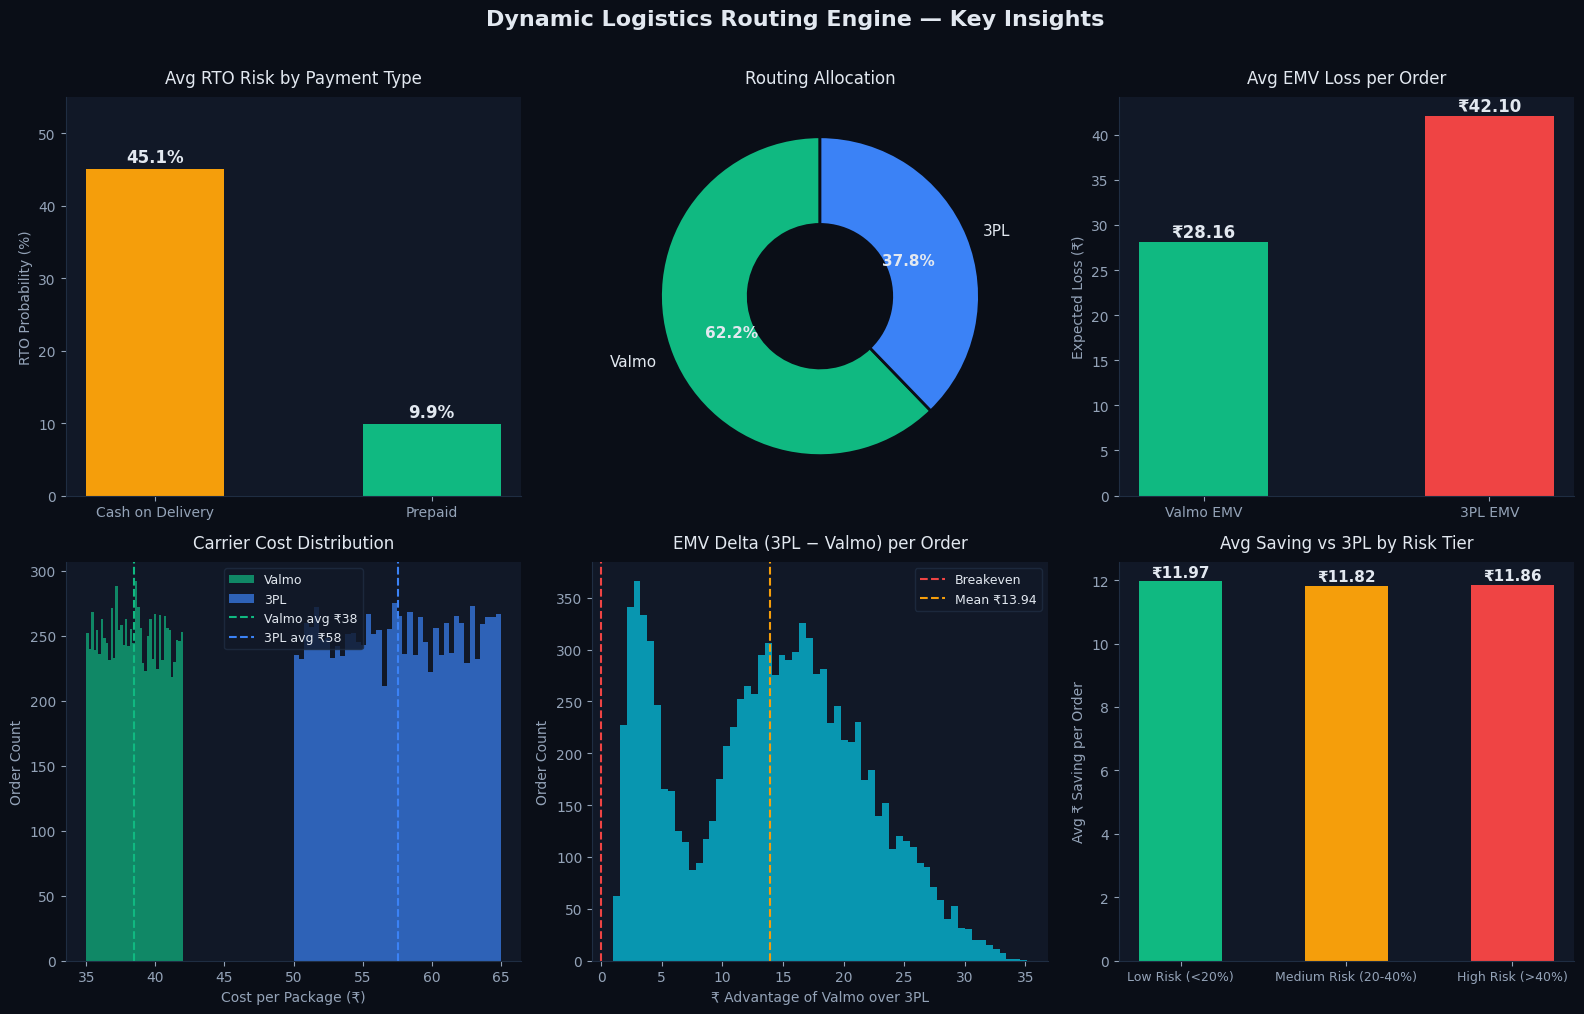

✅ All 6 charts rendered and saved as routing_analysis.png


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Dynamic Logistics Routing Engine — Key Insights',
             fontsize=16, fontweight='bold', color='#e2e8f0', y=1.01)

BLUE  = '#3b82f6'
GREEN = '#10b981'
AMBER = '#f59e0b'
RED   = '#ef4444'
CYAN  = '#06b6d4'
MUTED = '#64748b'

# ── Chart 1: RTO Risk COD vs Prepaid ─────────────────────────────────────────
ax = axes[0, 0]
categories = ['Cash on Delivery', 'Prepaid']
rto_vals   = [
    df[df['Payment_Type']=='Cash on Delivery']['Historical_PIN_Risk'].mean()*100,
    df[df['Payment_Type']=='Prepaid']['Historical_PIN_Risk'].mean()*100
]
bars = ax.bar(categories, rto_vals, color=[AMBER, GREEN], width=0.5, edgecolor='none')
for bar, val in zip(bars, rto_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4,
            f'{val:.1f}%', ha='center', va='bottom', fontweight='bold',
            color='#e2e8f0', fontsize=12)
ax.set_title('Avg RTO Risk by Payment Type', color='#e2e8f0', fontsize=12, pad=10)
ax.set_ylabel('RTO Probability (%)', color='#94a3b8')
ax.set_ylim(0, 55)
ax.tick_params(axis='x', labelsize=10)

# ── Chart 2: Routing allocation donut ────────────────────────────────────────
ax = axes[0, 1]
sizes  = [counts['Valmo'], counts['3PL']]
colors = [GREEN, BLUE]
wedges, texts, autotexts = ax.pie(
    sizes, labels=['Valmo', '3PL'], colors=colors,
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(width=0.55, edgecolor='#0a0e17', linewidth=2),
    textprops=dict(color='#e2e8f0', fontsize=11)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
ax.set_title('Routing Allocation', color='#e2e8f0', fontsize=12, pad=10)

# ── Chart 3: EMV comparison bar ───────────────────────────────────────────────
ax = axes[0, 2]
emv_data  = [df['EMV_Valmo'].mean(), df['EMV_3PL'].mean()]
emv_labels= ['Valmo EMV', '3PL EMV']
emv_colors= [GREEN, RED]
bars = ax.bar(emv_labels, emv_data, color=emv_colors, width=0.45, edgecolor='none')
for bar, val in zip(bars, emv_data):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
            f'₹{val:.2f}', ha='center', va='bottom', fontweight='bold',
            color='#e2e8f0', fontsize=12)
ax.set_title('Avg EMV Loss per Order', color='#e2e8f0', fontsize=12, pad=10)
ax.set_ylabel('Expected Loss (₹)', color='#94a3b8')

# ── Chart 4: Cost distribution ────────────────────────────────────────────────
ax = axes[1, 0]
ax.hist(df['Valmo_Cost'], bins=40, color=GREEN,  alpha=0.7, label='Valmo',  edgecolor='none')
ax.hist(df['3PL_Cost'],   bins=40, color=BLUE,   alpha=0.7, label='3PL',    edgecolor='none')
ax.axvline(df['Valmo_Cost'].mean(), color=GREEN, linestyle='--', linewidth=1.5,
           label=f"Valmo avg ₹{df['Valmo_Cost'].mean():.0f}")
ax.axvline(df['3PL_Cost'].mean(),   color=BLUE,  linestyle='--', linewidth=1.5,
           label=f"3PL avg ₹{df['3PL_Cost'].mean():.0f}")
ax.set_title('Carrier Cost Distribution', color='#e2e8f0', fontsize=12, pad=10)
ax.set_xlabel('Cost per Package (₹)', color='#94a3b8')
ax.set_ylabel('Order Count',           color='#94a3b8')
ax.legend(fontsize=9, facecolor='#111827', edgecolor='#1f2d42',
          labelcolor='#e2e8f0')

# ── Chart 5: EMV delta histogram ──────────────────────────────────────────────
ax = axes[1, 1]
ax.hist(df['EMV_Delta'], bins=60, color=CYAN, alpha=0.8, edgecolor='none')
ax.axvline(0, color=RED,  linestyle='--', linewidth=1.5, label='Breakeven')
ax.axvline(df['EMV_Delta'].mean(), color=AMBER, linestyle='--',
           linewidth=1.5, label=f"Mean ₹{df['EMV_Delta'].mean():.2f}")
ax.set_title('EMV Delta (3PL − Valmo) per Order', color='#e2e8f0', fontsize=12, pad=10)
ax.set_xlabel('₹ Advantage of Valmo over 3PL', color='#94a3b8')
ax.set_ylabel('Order Count', color='#94a3b8')
ax.legend(fontsize=9, facecolor='#111827', edgecolor='#1f2d42', labelcolor='#e2e8f0')

# ── Chart 6: Savings by risk tier ─────────────────────────────────────────────
ax = axes[1, 2]
tier_savings = (df.groupby('Risk_Tier', observed=True)['Cost_Saving_vs_3PL']
                  .mean().reset_index())
tier_colors = [GREEN, AMBER, RED]
bars = ax.bar(tier_savings['Risk_Tier'], tier_savings['Cost_Saving_vs_3PL'],
              color=tier_colors, width=0.5, edgecolor='none')
for bar, val in zip(bars, tier_savings['Cost_Saving_vs_3PL']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
            f'₹{val:.2f}', ha='center', va='bottom', fontweight='bold',
            color='#e2e8f0', fontsize=11)
ax.set_title('Avg Saving vs 3PL by Risk Tier', color='#e2e8f0', fontsize=12, pad=10)
ax.set_ylabel('Avg ₹ Saving per Order', color='#94a3b8')
ax.tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.savefig('routing_analysis.png', dpi=150, bbox_inches='tight',
            facecolor='#0a0e17')
plt.show()
print("✅ All 6 charts rendered and saved as routing_analysis.png")


## Step 8 — SQL Queries Reference



In [ ]:
sql_queries = {

"Query 1 — RTO Rate by Payment Type": '''
-- Identifies which payment methods carry higher return risk
SELECT
    Payment_Type,
    COUNT(Order_ID)                                                    AS Total_Orders,
    ROUND(SUM(CASE WHEN Status = 'RTO' THEN 1 ELSE 0 END) * 100.0
          / COUNT(Order_ID), 2)                                        AS Historical_RTO_Pct,
    ROUND(AVG(Fulfillment_Cost), 2)                                    AS Avg_Cost
FROM Meesho_Fulfillment_Logs
GROUP BY Payment_Type
ORDER BY Historical_RTO_Pct DESC;
''',

"Query 2 — RTO Rate by PIN Code (Top 10 Risky)": '''
-- Identifies high-risk delivery zones for routing decisions
SELECT
    Destination_PIN,
    COUNT(Order_ID)                                                    AS Total_Shipments,
    ROUND(SUM(CASE WHEN Status = 'RTO' THEN 1 ELSE 0 END) * 100.0
          / COUNT(Order_ID), 2)                                        AS RTO_Rate_Pct,
    ROUND(AVG(Forward_Cost + Reverse_Cost), 2)                        AS Avg_Total_Cost_On_RTO
FROM Meesho_Fulfillment_Logs
WHERE Order_Date >= DATEADD(month, -6, GETDATE())
GROUP BY Destination_PIN
HAVING COUNT(Order_ID) >= 50                      -- min volume threshold
ORDER BY RTO_Rate_Pct DESC
LIMIT 10;
''',

"Query 3 — EMV Calculation in SQL": '''
-- Computes EMV for both carriers per order
SELECT
    Order_ID,
    Payment_Type,
    Destination_PIN,
    Historical_RTO_Rate,
    Valmo_Rate,
    Third_Party_Rate,
    ROUND(Historical_RTO_Rate * (Valmo_Rate * 2), 2)        AS EMV_Valmo,
    ROUND(Historical_RTO_Rate * (Third_Party_Rate * 2), 2)  AS EMV_3PL,
    CASE
        WHEN Valmo_Serviceable = FALSE          THEN '3PL'
        WHEN Order_Value > 2200                 THEN '3PL'
        WHEN Historical_RTO_Rate * Valmo_Rate * 2
           < Historical_RTO_Rate * Third_Party_Rate * 2     THEN 'Valmo'
        ELSE '3PL'
    END                                                     AS Recommended_Partner
FROM logistics_orders
WHERE Order_Date BETWEEN '2024-01-01' AND '2024-01-31'
ORDER BY Order_ID;
''',

"Query 4 — Monthly Cost Saving Summary": '''
-- Tracks financial impact of EMV routing vs uniform 3PL assignment
SELECT
    FORMAT(Order_Date, 'yyyy-MM')                               AS Month,
    COUNT(*)                                                    AS Total_Orders,
    SUM(CASE WHEN Assigned_Partner = 'Valmo' THEN 1 ELSE 0 END) AS Valmo_Orders,
    ROUND(AVG(Final_Fulfillment_Cost), 2)                       AS Avg_Actual_Cost,
    ROUND(AVG(Third_Party_Rate), 2)                             AS Avg_3PL_Baseline,
    ROUND(SUM(Third_Party_Rate - Final_Fulfillment_Cost), 0)    AS Total_Monthly_Saving
FROM routed_orders
GROUP BY FORMAT(Order_Date, 'yyyy-MM')
ORDER BY Month;
'''
}

for title, query in sql_queries.items():
    print(f"{'='*65}")
    print(f"  {title}")
    print(f"{'='*65}")
    print(query)


  Query 1 — RTO Rate by Payment Type

-- Identifies which payment methods carry higher return risk
SELECT
    Payment_Type,
    COUNT(Order_ID)                                                    AS Total_Orders,
    ROUND(SUM(CASE WHEN Status = 'RTO' THEN 1 ELSE 0 END) * 100.0
          / COUNT(Order_ID), 2)                                        AS Historical_RTO_Pct,
    ROUND(AVG(Fulfillment_Cost), 2)                                    AS Avg_Cost
FROM Meesho_Fulfillment_Logs
GROUP BY Payment_Type
ORDER BY Historical_RTO_Pct DESC;

  Query 2 — RTO Rate by PIN Code (Top 10 Risky)

-- Identifies high-risk delivery zones for routing decisions
SELECT
    Destination_PIN,
    COUNT(Order_ID)                                                    AS Total_Shipments,
    ROUND(SUM(CASE WHEN Status = 'RTO' THEN 1 ELSE 0 END) * 100.0
          / COUNT(Order_ID), 2)                                        AS RTO_Rate_Pct,
    ROUND(AVG(Forward_Cost + Reverse_Cost), 2)                        AS Avg

## Step 9 — Export for Power BI

In [ ]:
# Final column selection for Power BI
export_cols = [
    'Order_ID', 'Order_Value_INR', 'Payment_Type', 'Is_COD',
    'Valmo_Serviceable', 'High_Value_Order',
    'Historical_PIN_Risk', 'Risk_Tier',
    'Valmo_Cost', '3PL_Cost',
    'EMV_Valmo', 'EMV_3PL', 'EMV_Delta',
    'Assigned_Partner', 'Final_Fulfillment_Cost', 'Cost_Saving_vs_3PL'
]

df_export = df[export_cols].copy()
df_export['Risk_Tier'] = df_export['Risk_Tier'].astype(str)

df_export.to_csv('Logistics_PowerBI_Data.csv', index=False)

print("✅ CSV exported: Logistics_PowerBI_Data.csv")
print(f"   Rows    : {len(df_export):,}")
print(f"   Columns : {len(df_export.columns)}")
print(f"\n   Column list:")
for i, col in enumerate(df_export.columns, 1):
    print(f"   {i:>2}. {col}")

print(f"\n{'─'*50}")
print("  FINAL SUMMARY")
print(f"{'─'*50}")
print(f"  Total orders processed    : {len(df):,}")
print(f"  Routed to Valmo           : {counts['Valmo']:,} ({pct['Valmo']:.1f}%)")
print(f"  Routed to 3PL             : {counts['3PL']:,} ({pct['3PL']:.1f}%)")
print(f"  Avg RTO rate              : {df['Historical_PIN_Risk'].mean()*100:.1f}%")
print(f"  Avg Valmo cost            : ₹{df['Valmo_Cost'].mean():.2f}")
print(f"  Avg 3PL cost              : ₹{df['3PL_Cost'].mean():.2f}")
print(f"  Total saving vs all-3PL   : ₹{total_saving:,.0f}")
print(f"  Avg saving per order      : ₹{avg_saving:.2f}")
print(f"{'─'*50}")
print("\n🎯 Project complete. Open Logistics_PowerBI_Data.csv in Power BI.")


✅ CSV exported: Logistics_PowerBI_Data.csv
   Rows    : 10,000
   Columns : 16

   Column list:
    1. Order_ID
    2. Order_Value_INR
    3. Payment_Type
    4. Is_COD
    5. Valmo_Serviceable
    6. High_Value_Order
    7. Historical_PIN_Risk
    8. Risk_Tier
    9. Valmo_Cost
   10. 3PL_Cost
   11. EMV_Valmo
   12. EMV_3PL
   13. EMV_Delta
   14. Assigned_Partner
   15. Final_Fulfillment_Cost
   16. Cost_Saving_vs_3PL

──────────────────────────────────────────────────
  FINAL SUMMARY
──────────────────────────────────────────────────
  Total orders processed    : 10,000
  Routed to Valmo           : 6,223 (62.2%)
  Routed to 3PL             : 3,777 (37.8%)
  Avg RTO rate              : 36.6%
  Avg Valmo cost            : ₹38.48
  Avg 3PL cost              : ₹57.55
  Total saving vs all-3PL   : ₹118,747
  Avg saving per order      : ₹11.87
──────────────────────────────────────────────────

🎯 Project complete. Open Logistics_PowerBI_Data.csv in Power BI.


In [ ]:
from google.colab import files

files.download('Logistics_PowerBI_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>